In [6]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from astropy import units as u
from astropy import constants as const
import pickle
import time
from multiprocessing import Pool

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [19]:
data, var = load_data_and_var()

/Users/eleanorstuart/Desktop/krisp/thermo-idm/load_data_and_var.py:14: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  low_z_data = comb_data[comb_data['z_y'] < 0.2][comb_data['Sub-Cat']=='REFLEX'][['OName','AName', 'L500', 'z_y', 'MSZ']].rename(columns={'AName': 'Name'}).dropna()


In [20]:
data

,OName,Name,L500,z_y,MSZ,e_MSZ,E_MSZ,L_err
2,RXCJ0003.8+0203,A2700,0.846881,0.0924,2.238774,0.301448,0.282160,0.136707
3,RXCJ0006.0-3443,A2721,1.809494,0.1147,4.001657,0.226974,0.248869,0.211627
6,RXCJ0011.3-2851,A2734,1.086002,0.0620,2.606369,0.188038,0.182667,0.086428
9,RXCJ0013.6-1930,A0013,1.236332,0.0940,2.756623,0.245311,0.233331,0.124160
10,RXCJ0014.3-6604,A2746,2.827248,0.1599,3.030337,0.347930,0.328876,0.313974
...,...,...,...,...,...,...,...,...
541,RXCJ2344.2-0422,,1.852614,0.0786,3.116566,0.208566,0.176734,0.119209
543,RXCJ2347.7-2808,A4038,1.029501,0.0300,1.480293,0.107849,0.114748,0.035784
547,RXCJ2354.2-1024,A2670,1.336537,0.0765,2.761984,0.225417,0.216913,0.140721
549,RXCJ2357.0-3445,A4059,1.629622,0.0475,2.468719,0.149009,0.163126,0.084855


In [21]:
nfws_full = generate_nfws_from_combined_dataset_werr(data, var)

In [24]:
nfws = [n for n in nfws_full if n.energies.is_virialized_gaspari]

In [26]:
len(nfws)

111

In [28]:
max([n.z for n in nfws])

0.1926

In [29]:
zs = [nfw.z for nfw in nfws]
filtered_vir = [nfw.energies.virialization_fraction_gaspari for nfw in nfws]

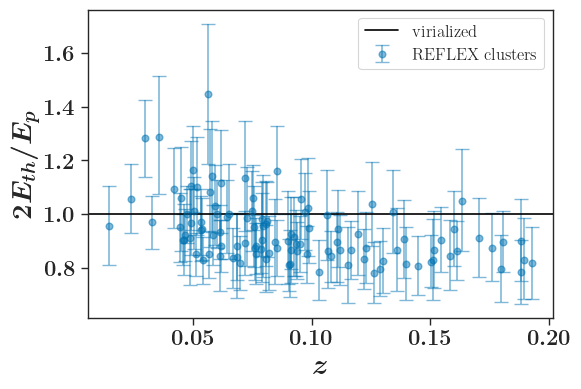

In [30]:
paper_plot()
fig = plt.figure()
plt.errorbar(zs, filtered_vir,
             yerr=[[v.minus for v in filtered_vir],[v.plus for v in filtered_vir]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label='REFLEX clusters')
plt.axhline(1.0, color='black', label='virialized')

plt.xlabel(f'$z$')
plt.ylabel(f'$2E_{{th}}/E_{{p}}$')
plt.legend()

In [31]:
savefig(fig,'plots/virialization0804.png') 

2024-08-04T10:34:51.323247: made plots/virialization0804.png


In [33]:
heating_rates = np.array([nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500) for nfw in nfws])
cooling_rates = np.array([nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500, vol_rate='gfe') for nfw in nfws])

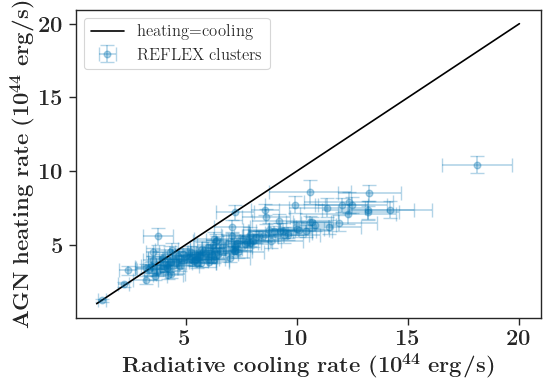

In [34]:
fig2 = plt.figure()
plt.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

plt.plot([1, 20], [1, 20], label='heating=cooling', c='k')
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
plt.legend()

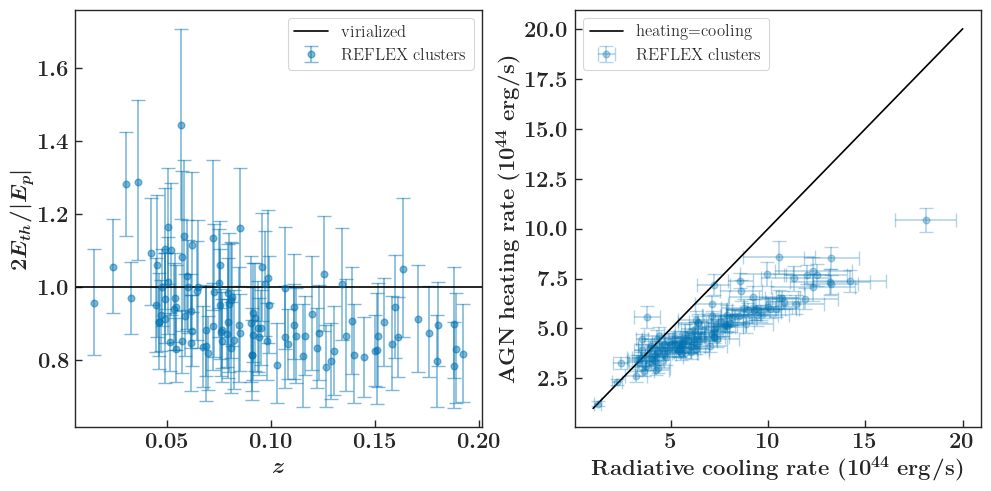

In [37]:
subplotsfig, (ax1, ax2) =  plt.subplots(1, 2, figsize=(10, 5))

# First subplot
ax1.errorbar(zs, filtered_vir,
             yerr=[[v.minus for v in filtered_vir],[v.plus for v in filtered_vir]], 
             fmt='o', capsize=5, capthick=1, alpha=0.5, label='REFLEX clusters')
ax1.axhline(1.0, color='black', label='virialized')
ax1.legend()
#ax1.set_title('Plot 1')
ax1.set_xlabel(f'$z$', size=16)
ax1.set_ylabel(f'$2E_{{th}}/|E_{{p}}|$', size=16)
ax1.tick_params(axis='y', direction='in')
ax1.tick_params(axis='x', direction='in')

# Second subplot
ax2.errorbar(cooling_rates/1e44, heating_rates/1e44,
             xerr=[[c.minus for c in cooling_rates/1e44],[c.plus for c in cooling_rates/1e44]],
             yerr=[[h.minus for h in heating_rates/1e44],[h.plus for h in heating_rates/1e44]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')

ax2.plot([1, 20], [1, 20], label='heating=cooling', c='k')
ax2.set_ylabel(f'$\mathrm{{AGN~heating~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.set_xlabel(f'$\mathrm{{Radiative~cooling~rate~(10^{{44}}~erg/s)}}$', size=16)
ax2.legend()
ax2.tick_params(axis='y', direction='in')
ax2.tick_params(axis='x', direction='in')
#ax2.set_title('Plot 2')

plt.tight_layout()

In [38]:
savefig(subplotsfig,'plots/equilibrium_plots0804.png') 

2024-08-04T10:37:29.101151: made plots/equilibrium_plots0804.png


In [271]:
nfws_full = generate_nfws_from_combined_dataset_werr(data, var)

In [273]:
nfws = [n for n in nfws_full if n.energies.is_virialized_gaspari]

In [274]:
test_nfw = nfws[1]

In [145]:
print(test_nfw.Tbs_norm[0], test_nfw.precalc.Tbs_norm_max[0], test_nfw.precalc.Tbs_norm_min[0])

0.1884814547516597 ± 4.246472207997518 0.1871360915433425 ± 0.0 0.189792969244163 ± 0.0


Text(0, 0.5, 'T/T500')

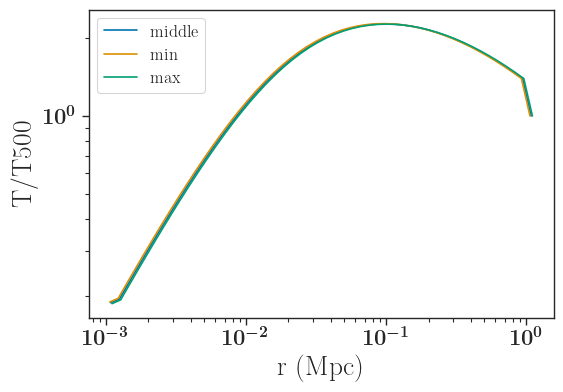

In [146]:
plt.loglog(test_nfw.rs_Mpc, test_nfw.Tbs_norm, label="middle")
plt.loglog(test_nfw.precalc.rs_min, test_nfw.precalc.Tbs_norm_min, label="min")
plt.loglog(test_nfw.precalc.rs_max, test_nfw.precalc.Tbs_norm_max, label="max")
plt.legend()
plt.xlabel('r (Mpc)')
plt.ylabel('T/T500')

In [148]:
print(test_nfw.rad_factors, test_nfw.precalc.rad_factors_max, test_nfw.precalc.rad_factors_min)

6.228439464682807e+46 (+1.1513851328047794e+46, -1.150566494400935e+46) 6.721312145305147e+46 ± 0.0 5.785790356096669e+46 ± 0.0


In [149]:
print(test_nfw.agn_factors, test_nfw.precalc.agn_factors_max, test_nfw.precalc.agn_factors_min)

1.3088984737294396 (+0.051224936877995876, -0.05065004063735856) 1.309097017816834 ± 0.0 1.308708517170528 ± 0.0


In [97]:
test_nfw.L_indep_factors, test_nfw.precalc.L_indep_factors_max, test_nfw.precalc.L_indep_factors_min

(array([<asymmetric_uncertainty_mod.core.a_u object at 0x135d02350>,
       dtype=object),
 array([<asymmetric_uncertainty_mod.core.a_u object at 0x138a6c8d0>,
       dtype=object),
 array([<asymmetric_uncertainty_mod.core.a_u object at 0x135cf7810>,
       dtype=object))

Text(0, 0.5, 'dm cooling factors')

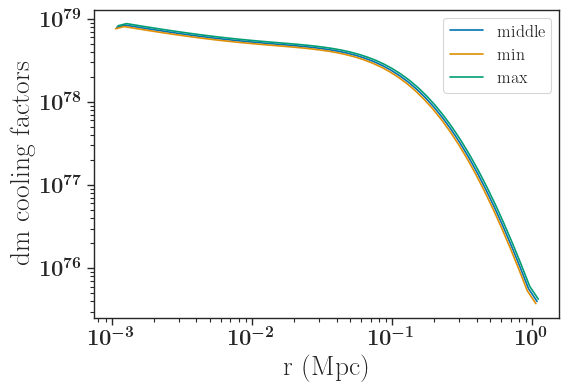

In [150]:
plt.loglog(test_nfw.rs_Mpc, test_nfw.L_indep_factors, label="middle")
plt.loglog(test_nfw.precalc.rs_min, test_nfw.precalc.L_indep_factors_min, label="min")
plt.loglog(test_nfw.precalc.rs_max, test_nfw.precalc.L_indep_factors_max, label="max")
plt.legend()
plt.xlabel('r (Mpc)')
plt.ylabel('dm cooling factors')

In [101]:
(u.Mpc/u.cm).to(1)**3

2.937998946096347e+73

In [275]:
mx = 1e-2
s0=1e-30
net_heating = test_nfw.L500_numerical(mx, s0)
net_heating

(7.801541510526321e+40, 1.385460842708138e+41, 4.894665692040661e+40)

In [256]:
np.log10(0)

/var/folders/99/vfh56jrs1nqcj8zqtcs5fkv40000gn/T/ipykernel_23108/135924841.py:1: RuntimeWarning: divide by zero encountered in log10
  np.log10(0)


-inf

In [267]:
nfws_full[4].L500_numerical(mx, s0)


(3.003781738305337e+41, 7.891509770967082e+41, 1.3333403955819385e+41)

In [198]:
test_nfw.L500

In [269]:
print(test_nfw.total_cooling_rate(0.001*test_nfw.R500, test_nfw.R500, vol_rate='gfe'))

9.733691088468478e+43 (+1.7904976957365526e+43, -1.7893972632026126e+43)


In [270]:
print(test_nfw.total_heating_rate(0.001*test_nfw.R500, test_nfw.R500, 0.1*test_nfw.R500))

5.185345243668135e+44 (+2.7192832020936836e+43, -2.7027835347238907e+43)


In [324]:
heating_rates = np.array([nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500) for nfw in nfws])
cooling_rates = np.array([nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500, vol_rate='gfe') for nfw in nfws])

0.0008964501279607095 (+3.76608459370164e-05, -4.0235280287856954e-05) 0.8964501279607096 (+0.03766084593701641, -0.04023528028785696)
0.0009523788156806168 (+2.2249111199518208e-05, -2.2903306956018364e-05) 0.9523788156806168 (+0.022249111199518206, -0.022903306956018363)
0.0009603296865886193 (+2.7095312646598048e-05, -2.8486477324700163e-05) 0.9603296865886193 (+0.02709531264659805, -0.028486477324700162)
0.0009693323852025517 (+3.5066524231009554e-05, -3.709816397576945e-05) 0.9693323852025516 (+0.035066524231009547, -0.03709816397576945)
0.0007873505917642288 (+3.2108205476040755e-05, -3.330255011050738e-05) 0.7873505917642287 (+0.03210820547604075, -0.033302550110507374)
0.001026475991436695 (+3.2141235745346e-05, -3.268495975729975e-05) 1.0264759914366948 (+0.032141235745346, -0.03268495975729975)
0.0009632274909175722 (+3.642999795058571e-05, -3.896917351306798e-05) 0.9632274909175722 (+0.036429997950585706, -0.03896917351306798)
0.000911362093796234 (+3.138584416027707e-05, -3

0.001037644198738534 (+4.8408374917649906e-05, -5.229781474768231e-05) 1.0376441987385339 (+0.0484083749176499, -0.0522978147476823)
0.0010550236520949394 (+4.4684265163911466e-05, -4.577277185589449e-05) 1.0550236520949394 (+0.04468426516391147, -0.045772771855894484)
0.0009906245646281652 (+1.915803540723498e-05, -1.9188103098595826e-05) 0.9906245646281653 (+0.019158035407234982, -0.019188103098595827)
0.0010149394864812113 (+2.5686114000458014e-05, -2.659656154212901e-05) 1.0149394864812114 (+0.025686114000458015, -0.02659656154212901)
0.0009359039360348821 (+2.724694868710966e-05, -3.1187220463653855e-05) 0.9359039360348821 (+0.027246948687109664, -0.031187220463653853)
0.0010650177548495465 (+3.645973968911603e-05, -3.8550105776406794e-05) 1.0650177548495465 (+0.036459739689116026, -0.038550105776406794)
0.0009293049687439272 (+3.0867348201310065e-05, -3.306560808727248e-05) 0.9293049687439272 (+0.03086734820131006, -0.03306560808727248)
0.0009813669957990804 (+3.3420292780592815e

(0.0, 2e+45)

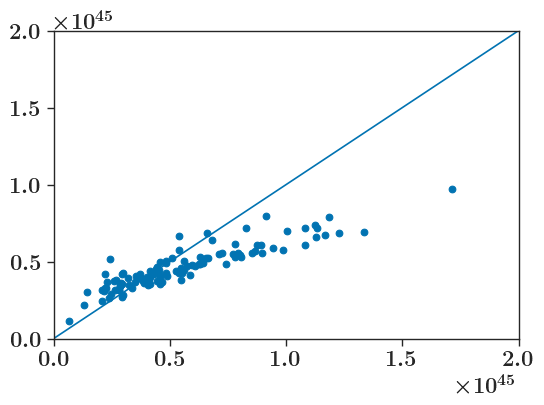

In [346]:
plt.scatter(10*cooling_rates, heating_rates)
plt.plot([0, 2e45], [0, 2e45])
plt.ylim(0, 2e45)
plt.xlim(0, 2e45)


In [289]:
Ls = [nfw.L500.value for nfw in nfws]

(array([44., 37., 15.,  5.,  7.,  2.,  0.,  0.,  0.,  1.]),
 array([0.034601 , 0.9770043, 1.9194076, 2.8618109, 3.8042142, 4.7466175,
        5.6890208, 6.6314241, 7.5738274, 8.5162307, 9.458634 ]),
 <BarContainer object of 10 artists>)

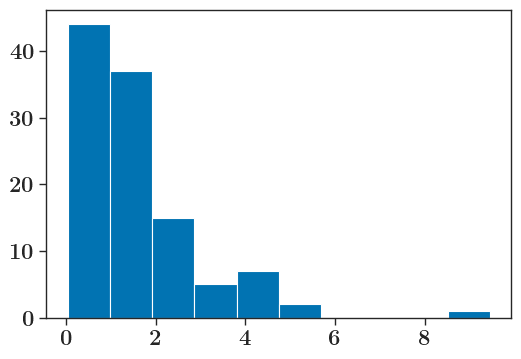

In [290]:
plt.hist(Ls)

In [300]:
rs = np.logspace(-3, 0)*test_nfw.R500

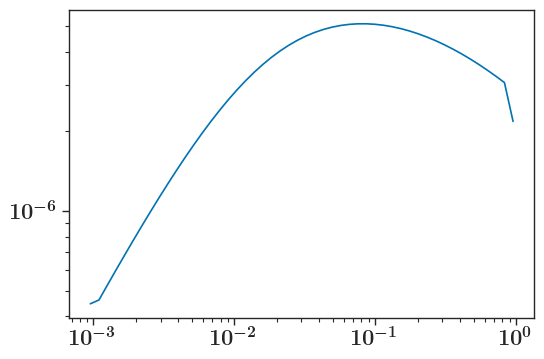

In [302]:
plt.loglog(rs, test_nfw.T_g(rs))

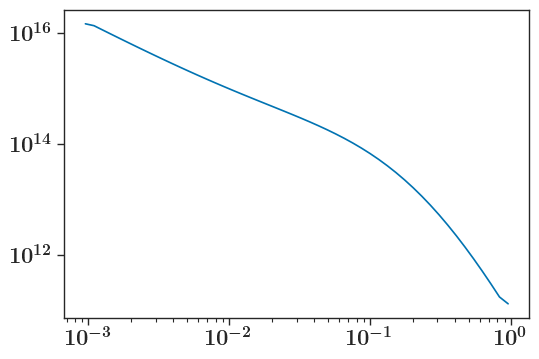

In [304]:
plt.loglog(rs, test_nfw.rho_g(rs))

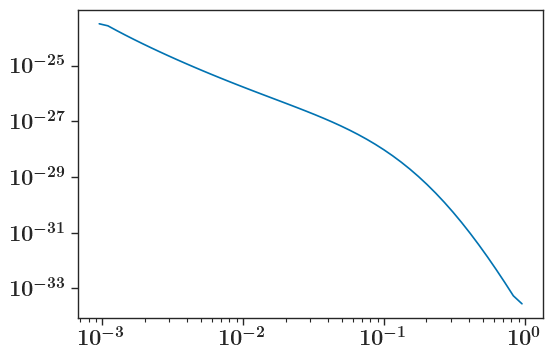

In [305]:
plt.loglog(rs, test_nfw.vol_cooling_rate(rs))

In [306]:
test_nfw.M500

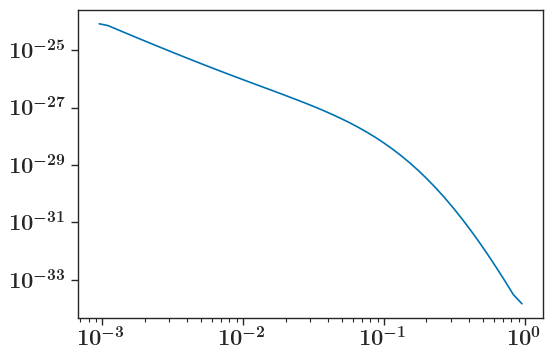

In [307]:
plt.loglog(rs, test_nfw.vol_radiative_cooling_rate_gfe(rs))

In [311]:
print(test_nfw.total_cooling_rate(0.001*test_nfw.R500, 
                            test_nfw.R500, 
                            vol_rate='gfe'))

0.9523788156806168 (+0.022249111199518206, -0.022903306956018363)
4.853273513341661e+43 (+1.0613952394234483e+43, -1.0616031868535862e+43)


In [312]:
(u.Mpc/u.cm).to(1)

3.085677581491367e+24

In [314]:
print(test_nfw.rad_factors)

9.647666056146339e+39 (+2.119921941062843e+39, -2.1204051969573043e+39)


In [318]:
T500k=test_nfw.T500*u.GeV.to(u.K, equivalencies=u.temperature_energy())

In [320]:
print(test_nfw.rad_factors * np.sqrt(T500k))

4.853273513341662e+43 (+1.277880112006319e+43, -1.2766967518172566e+43)


In [ ]:
print(test_nfw.total_heating_rate(0.001*test_nfw.R500, 
                            test_nfw.R500, 
                            vol_rate='gfe'))

In [325]:
(1e37*u.W).to(u.erg/u.s)

<Quantity 1.e+44 erg / s>

In [326]:
np.logspace(-3, 0, num=50)

array([0.001     , 0.0011514 , 0.00132571, 0.00152642, 0.00175751,
       0.00202359, 0.00232995, 0.0026827 , 0.00308884, 0.00355648,
       0.00409492, 0.00471487, 0.00542868, 0.00625055, 0.00719686,
       0.00828643, 0.00954095, 0.01098541, 0.01264855, 0.01456348,
       0.01676833, 0.01930698, 0.02222996, 0.02559548, 0.02947052,
       0.03393222, 0.0390694 , 0.04498433, 0.05179475, 0.05963623,
       0.06866488, 0.07906043, 0.09102982, 0.10481131, 0.12067926,
       0.13894955, 0.15998587, 0.184207  , 0.21209509, 0.24420531,
       0.28117687, 0.32374575, 0.37275937, 0.42919343, 0.49417134,
       0.5689866 , 0.65512856, 0.75431201, 0.86851137, 1.        ])

2.937998946096347e+73

In [329]:
print(test_nfw.total_cooling_rate(0.001*test_nfw.R500, 
                            test_nfw.R500, 
                            vol_rate='gfe', Tb=test_nfw.T_g(rs)))

0.0009523788156806168 (+2.2249111199518208e-05, -2.2903306956018364e-05) 0.9523788156806168 (+0.022249111199518206, -0.022903306956018363)
4.853273513341661e+43 (+1.0613952394234483e+43, -1.0616031868535862e+43)


In [ ]:
test_nfw.T_g(rs)

(1e-30, 1e-25)

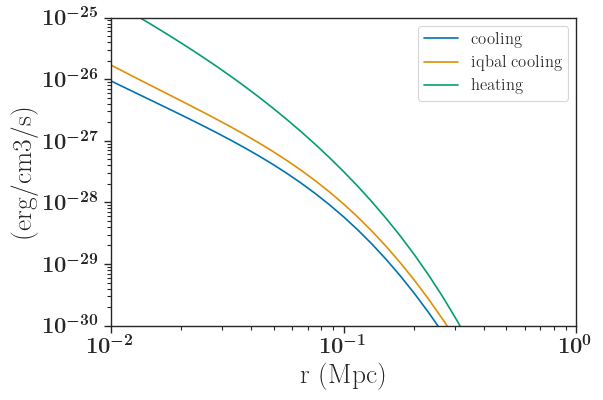

In [338]:
plt.loglog(rs, test_nfw.vol_radiative_cooling_rate_gfe(rs), label="cooling")
plt.loglog(rs, test_nfw.vol_cooling_rate(rs), label="iqbal cooling")
plt.loglog(rs, test_nfw.vol_heating_rate(rs, 0.1*test_nfw.R500), label='heating')
plt.legend()
plt.xlabel('r (Mpc)')
plt.ylabel('(erg/cm3/s)')
plt.xlim(1e-2, 1)
plt.ylim(1e-30, 1e-25)